**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_022_초급_회귀_주식종목평가

### **주식 종목 평가 — <span style="color:darkgreen">다음 달 수익률(%)</span> 예측 모델 개발**
---

- 도메인 : 주식 종목 평가
- 목  표 : 종목의 다음 달 수익률(%)을 예측하는 인공지능모델 개발
- 종목 수가 많아 누리증권는 분석 우선순위를 정할 객관적 기준이 필요하다.
- 퀀트팀은 재무·시장 지표로 종목의 향후 흐름을 예측하는 보조 모델을 만들려 한다.
- 제공되는 데이터는 종목 단위로 정리된 약 1,010건의 기록이다.
- 모델이 다음 달 수익률(%)을 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 누리증권의 데이터로 종목의 다음 달 수익률(%)을 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, min, max, idxmax, iloc, quantile, reset_index, drop, dropna, sum, isnull, duplicated, drop_duplicates, get_dummies, info, DataFrame, sort_values, columns, shape) · seaborn(barplot) · matplotlib(show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, MinMaxScaler, fit_transform, transform, DecisionTreeRegressor, fit, RandomForestRegressor, feature_importances_, predict, r2_score) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, Dropout, history)
- 난이도 : 초급 (설계 난이도 점수 2.43 / 5)
- 예상 소요 시간 : 약 111분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 주식 종목 평가 (금융)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- Next_Ret              : 다음 달 수익률(%)
- E_Record_Id           : 레코드 식별번호
- FE_Ret_1m             : 최근 1개월 수익률(%)
- FE_Volatility         : 연환산 변동성(%)
- FE_Pbr                : 주가순자산비율(PBR)
- FE_Foreign_Ratio      : 외국인 보유비율(%)
- FE_Debt_Ratio         : 부채비율(%)
- FE_Roe                : 자기자본이익률(ROE,%)
- FE_Analyst_Cnt        : 분석 리포트 수
- E_Sector              : 업종
- E_Cap_Class           : 시가총액 구분
- E_Exchange            : 상장 시장
- E_Theme               : 주요 테마

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석에 널리 사용되는 파이썬 라이브러리 pandas 를 사용하려고 합니다. 별칭(alias)을 pd 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- 사용할 라이브러리 : `pandas`
- 붙일 별칭 : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

In [3]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'pandas'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 6글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pan___ as pd

정답01 = 'pan___'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델링에 사용할 데이터 파일을 불러오려고 합니다. 아래 안내대로 파일을 읽어 df_raw 에 저장하고 처음 3개 행을 확인하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 읽은 결과를 담을 변수 : df_raw
    - 파일은 이 노트북과 같은 폴더에 있습니다
    - 읽어 올 파일 : data.csv
- **[정답02]** 읽어 온 데이터의 **행(row)의 개수** 를 입력하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [6]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd

df_raw = pd.read_csv('./data.csv')
df_raw.head(3)

print(df_raw.shape[0])


1007


In [7]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 1007

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 df_raw 로 행(row)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_raw = pd.read_csv('./data.csv')
df_raw.head(3)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(df_raw.shape[__])
```

</details>

### **3. 최근 1개월 수익률(%)(FE_Ret_1m)의 값이 어느 범위에 걸쳐 있는지, 가장 큰 값이 어느 행에 있는지 확인할 계획입니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(min, max, idxmax) | 난이도: 기초 | 예상 시간: 3분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- df_raw 의 FE_Ret_1m 컬럼에서 최솟값을 `col_min`, 최댓값을 `col_max`, **최댓값이 있는 행의 인덱스**를 `max_idx` 에 저장하세요
    - 최솟값은 `min()`, 최댓값은 `max()`, 최댓값의 인덱스는 `idxmax()` 를 사용하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [13]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

col_min = df_raw['FE_Ret_1m'].min()
col_max = df_raw['FE_Ret_1m'].max()
max_idx = df_raw['FE_Ret_1m'].idxmax()

In [12]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'idxmax'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

최솟값·최댓값을 구하는 메서드와, 최댓값의 위치(인덱스)를 구하는 메서드를 각각 쓰세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `min`, `max`, `idxmax`. 정답은 6글자이고 첫 글자는 `i` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
col_min = df_raw['FE_Ret_1m'].min()
col_max = df_raw['FE_Ret_1m'].max()
max_idx = df_raw['FE_Ret_1m'].idx___()

정답03 = 'idx___'   # 빈칸에 넣은 단어
```

</details>

### **4. 컬럼 이름이 아니라 **위치 번호**로 데이터를 선택할 계획입니다. iloc 를 활용하세요.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(iloc) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- df_raw 에서 행 위치 15, 열 위치 5 (둘 다 0부터 시작)의 값을 `iloc` 로 선택해 `cell` 에 저장하세요
    - 이어서 첫 5개 행, 첫 3개 열만 `iloc` 슬라이싱으로 선택해 `sub` 에 보관하세요
- **[정답04]** `cell` 의 값을 소수점 아래 둘째 자리까지 기입하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [15]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
cell = df_raw.iloc[15, 5]
sub = df_raw.iloc[:5, :3]
round(cell,2)


np.float64(24.7)

In [16]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 24.7

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

위치 기반 선택에는 iloc 를 쓰고, 슬라이스는 `시작:끝` 형태입니다. cell 값을 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `iloc`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
cell = df_raw.iloc[15, 5]
sub = df_raw.iloc[:5, :3]

# [정답04] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(cell, __)
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 자기자본이익률(ROE,%)(FE_Roe) 컬럼의 이상치를 IQR 기준으로 제거하고자 합니다. 제시된 가이드에 맞춰 처리하십시오.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- 사분위수(Q1, Q3)와 IQR 을 계산하세요
- lower_fence = Q1 - 3.0 x IQR, upper_fence = Q3 + 3.0 x IQR 로 정의하세요
- FE_Roe 이(가) 두 fence 밖에 있는 행을 삭제하세요
- 식별자 컬럼 E_Record_Id 도 삭제하고 인덱스를 0부터 다시 매겨 df_clean 에 저장하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [21]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

q1 = df_raw['FE_Roe'].quantile(0.25)
q3 = df_raw['FE_Roe'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 3.0 * iqr
upper_fence = q3 + 3.0 * iqr

is_out = (df_raw['FE_Roe'] > upper_fence) | (df_raw['FE_Roe'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['E_Record_Id']).reset_index(drop=True)

In [22]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'quantile'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`. 정답은 8글자이고 첫 글자는 `q` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = df_raw['FE_Roe'].quan____(0.25)
q3 = df_raw['FE_Roe'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 3.0 * iqr
upper_fence = q3 + 3.0 * iqr

is_out = (df_raw['FE_Roe'] > upper_fence) | (df_raw['FE_Roe'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['E_Record_Id']).reset_index(drop=True)

정답05 = 'quan____'   # 빈칸에 넣은 단어
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 아래 가이드에 따라 결측치를 처리하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 대상 데이터프레임 : df_clean
- 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
- 전처리가 반영된 데이터프레임은 변수명 df_filled 에 담으세요
- 결측치가 사라졌는지 확인하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답06]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [23]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

print( '결측치 처리 전\n', df_clean.isnull().sum() )
df_filled = df_clean.dropna()
print( '결측치 처리 후\n', df_filled.isnull().sum() )

결측치 처리 전
 Next_Ret             0
FE_Ret_1m            0
FE_Volatility        0
FE_Pbr               0
FE_Foreign_Ratio     0
FE_Debt_Ratio        0
FE_Roe               0
FE_Analyst_Cnt      52
E_Sector             0
E_Cap_Class          0
E_Exchange           0
E_Theme              0
dtype: int64
결측치 처리 후
 Next_Ret            0
FE_Ret_1m           0
FE_Volatility       0
FE_Pbr              0
FE_Foreign_Ratio    0
FE_Debt_Ratio       0
FE_Roe              0
FE_Analyst_Cnt      0
E_Sector            0
E_Cap_Class         0
E_Exchange          0
E_Theme             0
dtype: int64


In [24]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 'isnull'

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 결측치 여부를 True/False 로 돌려주는 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`. 정답은 6글자이고 첫 글자는 `i` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
print( '결측치 처리 전\n', df_clean.isn___().sum() )
df_filled = df_clean.dropna()
print( '결측치 처리 후\n', df_filled.isnull().sum() )

정답06 = 'isn___'   # 빈칸에 넣은 단어
```

</details>

### **7. 데이터에 완전히 동일한 행이 중복되어 있으면 모델이 편향될 수 있습니다. 중복 데이터를 처리하십시오.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(sum, reset_index, duplicated, drop_duplicates) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_filled`
- 대상 데이터프레임 : df_filled
- `duplicated()` 로 중복 행의 개수를 구해 변수 `dup_count` 에 저장하고, `drop_duplicates()` 로 중복 행을 제거한 뒤 인덱스를 0부터 다시 매겨 df_filled 에 보관하세요
- **[정답07]** 제거된 중복 행(`dup_count`)은 몇 개로 나타나나요?
- 남은 문자열 컬럼 E_Sector, E_Cap_Class, E_Exchange, E_Theme 을(를) get_dummies(drop_first=True)로 인코딩해 df_final 에 담으세요
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [25]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd

dup_count = df_filled.duplicated().sum()
print('중복 행 개수:', dup_count)
df_filled = df_filled.drop_duplicates().reset_index(drop=True)

df_final = pd.get_dummies(data=df_filled, columns=['E_Sector', 'E_Cap_Class', 'E_Exchange', 'E_Theme'], drop_first=True)
df_final.info()

df_filled.duplicated().sum()


중복 행 개수: 9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 933 entries, 0 to 932
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Next_Ret          933 non-null    float64
 1   FE_Ret_1m         933 non-null    float64
 2   FE_Volatility     933 non-null    float64
 3   FE_Pbr            933 non-null    float64
 4   FE_Foreign_Ratio  933 non-null    float64
 5   FE_Debt_Ratio     933 non-null    float64
 6   FE_Roe            933 non-null    float64
 7   FE_Analyst_Cnt    933 non-null    float64
 8   E_Sector_금융       933 non-null    bool   
 9   E_Sector_바이오      933 non-null    bool   
 10  E_Sector_산업재      933 non-null    bool   
 11  E_Sector_소비재      933 non-null    bool   
 12  E_Cap_Class_소형    933 non-null    bool   
 13  E_Cap_Class_중형    933 non-null    bool   
 14  E_Exchange_코스피    933 non-null    bool   
 15  E_Theme_모멘텀       933 non-null    bool   
 16  E_Theme_배당        933 non-null   

np.int64(0)

In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [26]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = 9

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

중복 여부를 불리언으로 구해 합계를 센 뒤, 중복을 제거합니다. 남은 문자열 컬럼을 모두 0/1 컬럼으로 바꿉니다. duplicated() 결과의 합계입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `duplicated`, `drop_duplicates`, `reset_index`, `pd.get_dummies`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

dup_count = df_filled.duplicated().sum()
print('중복 행 개수:', dup_count)
df_filled = df_filled.drop_duplicates().reset_index(drop=True)

df_final = pd.get_dummies(data=df_filled, columns=['E_Sector', 'E_Cap_Class', 'E_Exchange', 'E_Theme'], drop_first=True)
df_final.info()

# [정답07] 실행한 결과를 입력하세요
df_filled.duplicated().sum()
```

</details>

### **8. 모델 성능을 확인할 검증 데이터를 따로 떼어 두려고 합니다. 아래 가이드에 따라 분리하세요.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 대상 데이터프레임 : df_final
- 다음 달 수익률(%)(Next_Ret) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
- 데이터를 훈련 85 : 검증 15 로 분할합니다 (test_size=0.15)
- scikit-learn 의 train_test_split 함수를 활용하세요
- 난수 시드(random_state)는 2024 로 설정하세요
- 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [28]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = df_final.drop('Next_Ret', axis=1)
y = df_final['Next_Ret']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.15, random_state=2024)

In [29]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'train_test_split'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 16글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('Next_Ret', axis=1)
y = df_final['Next_Ret']

X_train, X_valid, y_train, y_valid = train_te________(X, y, test_size=0.15, random_state=2024)

정답08 = 'train_te________'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (최솟값 0~최댓값 1 정규화)**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(MinMaxScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 가이드에 따라 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요
    - sklearn.preprocessing 에서 MinMaxScaler 를 import 하세요
    - MinMaxScaler 를 ss 변수에 지정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 저장하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 저장하세요
- **[정답09]** MinMaxScaler 적용 후 검증 데이터(X_valid)의 **최댓값**을 소수점 둘째 자리까지 기입하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [30]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

import numpy as np

from sklearn.preprocessing import MinMaxScaler

ss = MinMaxScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)
print(X_valid.max())

1.0


In [31]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = 1.0

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최댓값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.max`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import MinMaxScaler

ss = MinMaxScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.max(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 다음 달 수익률(%)(Next_Ret)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. DecisionTree와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(DecisionTreeRegressor, fit, RandomForestRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=3, min_samples_leaf=2
    - 난수 시드(random_state) : 0
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=150, max_depth=4
    - 난수 시드(random_state) : 0
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `dt`(DecisionTree) 의 **훈련 데이터** 점수 `dt.score(X_train, y_train)` (결정계수(R2))를 소수점 셋째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [32]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=3, min_samples_leaf=2, random_state=0)
dt.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=150, max_depth=4, random_state=0)
rf.fit(X_train, y_train)

round(dt.score(X_train, y_train), 3)

0.423

In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [33]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 0.423

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `DecisionTreeRegressor`, `fit`, `RandomForestRegressor`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=3, min_samples_leaf=2, random_state=0)
dt.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=150, max_depth=4, random_state=0)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(dt.score(X_train, y_train), __)
```

</details>

### **11. 모델의 해석력과 개선 방향을 이해하기 위해 RandomForest 모델의 변수중요도를 파악하려고 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, sort_values, columns) · seaborn(barplot) · matplotlib(show) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `rf`
- 아래 안내대로 모델의 변수중요도를 파악하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - 앞서 학습시킨 RandomForest 모델 `rf` 를 사용하세요
    - 변수중요도 점수와 변수 이름(X.columns)을 매핑하여 DataFrame(fi)을 만드세요
    - 변수중요도 점수를 기준으로 내림차순 정렬하고 Top 8 개만 선정하세요
    - 변수중요도 점수를 막대 그래프(seaborn barplot)로 시각화하세요
- **[정답11]** 출력된 그래프에서 **가장 높은 중요도**를 보이는 변수명을 쓰세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


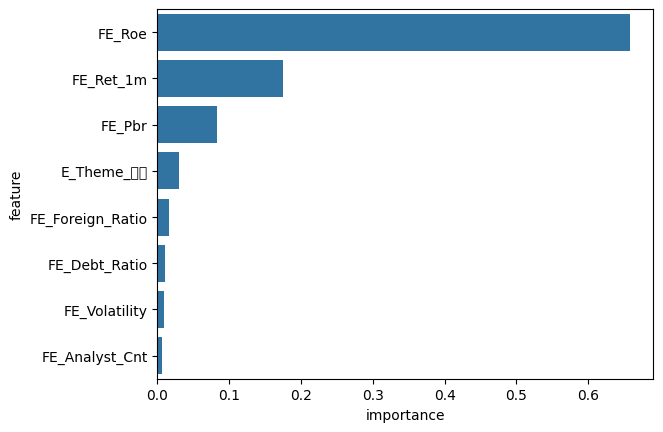

             feature  importance
5             FE_Roe    0.657814
0          FE_Ret_1m    0.174313
2             FE_Pbr    0.082754
16        E_Theme_성장    0.030281
3   FE_Foreign_Ratio    0.015866
4      FE_Debt_Ratio    0.010810
1      FE_Volatility    0.009406
6     FE_Analyst_Cnt    0.006983


In [34]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:8]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()
print(fi)

In [35]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'FE_Roe'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

변수 중요도를 DataFrame 으로 만들고 정렬해 그리는 흐름을 점검하세요. fi 의 첫 번째 행(가장 큰 중요도)의 feature 값을 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `sort_values`, `iloc`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:8]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
fi['____'].iloc[__]
```

</details>

### **12. 앞서 학습시킨 DecisionTree와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, r2_score) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `rf`
- 아래 안내대로 각 모델의 R2(결정계수) 를 산출하려는데 실행 중 예외가 발생합니다. 코드의 오류를 바로잡으세요
    - 앞서 학습시킨 dt 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 R2(결정계수) 값을 각각 dt_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 R2(결정계수) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (DecisionTree / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [36]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import r2_score

y_pred_dt = dt.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

dt_score = r2_score(y_valid, y_pred_dt)
rf_score = r2_score(y_valid, y_pred_rf)
print(dt_score, rf_score)

0.14580490024699766 0.3146838541325845


In [37]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'RandomForest'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

R2(결정계수) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import r2_score

y_pred_dt = dt.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

dt_score = r2_score(y_valid, y_pred_dt)
rf_score = r2_score(y_valid, y_pred_rf)
print(dt_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(dt_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [38]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **13. 다음 달 수익률(%)(Next_Ret)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- 딥러닝 프레임워크는 tensorflow 를 씁니다
- 은닉층은 Dense 레이어 2개(노드 수 [64, 32]), 활성화 함수는 'elu' 로 하세요
- 첫 번째 은닉층 뒤에 Dropout(0.3) 층을 두세요
- EarlyStopping 으로 5번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 저장하세요
- 출력층은 노드 1개, activation='linear' 로 하세요
- compile 설정 : optimizer='adam', loss='mse', metrics=[mae]
- batch_size 는 32, epochs 는 20 로 학습하고 학습정보는 history 변수에 담으세요 (검증은 훈련 데이터의 20% 를 쓰는 validation_split=0.2 로 지정)
- 가이드에 없는 인자는 추가하지 말고 기본값으로 두세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [39]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(64, activation='elu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(32, activation='elu'),
    Dense(1, activation='linear')
])

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=32,
                    validation_split=0.2,
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 37.7644 - mae: 4.7761 - val_loss: 36.2793 - val_mae: 4.8157
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 35.7964 - mae: 4.7030 - val_loss: 35.1057 - val_mae: 4.7447
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 35.1792 - mae: 4.6682 - val_loss: 34.4209 - val_mae: 4.6931
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 33.9541 - mae: 4.5743 - val_loss: 33.6075 - val_mae: 4.6395
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 32.9499 - mae: 4.4953 - val_loss: 32.6866 - val_mae: 4.5819
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 31.9041 - mae: 4.4066 - val_loss: 31.6580 - val_mae: 4.5207
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30.7797 - mae: 4.3437 - val_loss: 30.4244 - val_mae: 4.4308
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 29.1783 - mae: 4.2193 - val_loss: 29.0762 - val_mae: 4.3336
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - los

In [40]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'linear'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 출력층의 활성화 함수 이름입니다. 문제 유형(이진/다중/회귀)을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 6글자이고 첫 글자는 `l` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(64, activation='elu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(32, activation='elu'),
    Dense(1, activation='lin___')
])

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=32,
                    validation_split=0.2,
                    callbacks=cb_list)

정답13 = 'lin___'   # 빈칸에 넣은 단어
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하십시오.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 1개의 그래프에 학습 Loss 과 검증 Loss 2가지를 모두 표시하세요
- 두 선의 범례 : 'train', 'val'
- 그래프의 타이틀은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

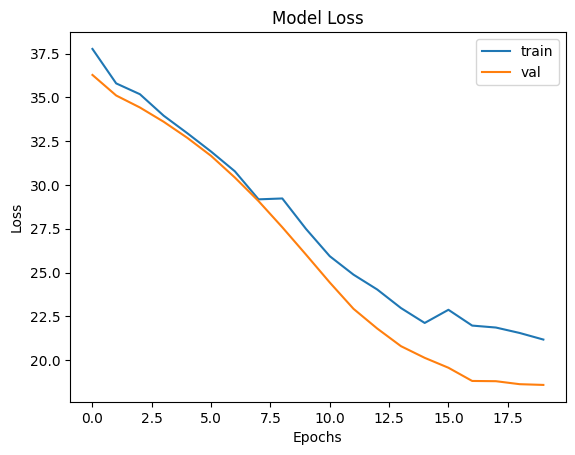

In [41]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

In [42]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'ylabel'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. y축 이름을 지정하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 6글자이고 첫 글자는 `y` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.yla___('Loss')
plt.legend(['train', 'val'])
plt.show()

정답14 = 'yla___'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.